In [5]:
import pandas as pd

# Read the CSV file into a DataFrame
df = pd.read_csv('../resident-list-district-6-clean.csv')

# Display the first few rows of the DataFrame
df.head()

,Unnamed: 0,Street .,Sffx,Street Name,Apt .,City,State,Zip,Mail Address,Mail Apt .,Mail City,Mail State,Mail Zip,Party,VS,Ward,Precinct,Age,Age_60_or_Above
0,37,319,NaN,CENTRE ST,3A,BOSTON,MA,2130,NaN,NaN,NaN,NaN,NaN,D,A,10,6,36,False
1,38,321,NaN,CENTRE ST,4,BOSTON,MA,2130,NaN,NaN,NaN,NaN,NaN,D,A,10,6,57,False
2,39,321,NaN,CENTRE ST,NaN,BOSTON,MA,2130,NaN,NaN,NaN,NaN,NaN,U,A,10,6,38,False
3,40,327,NaN,CENTRE ST,201,BOSTON,MA,2130,NaN,NaN,NaN,NaN,NaN,D,A,10,6,76,True
4,41,327,NaN,CENTRE ST,202,BOSTON,MA,2130,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10,6,29,False


In [6]:
# Assuming your DataFrame is named 'df'
filtered_df = df[df['Zip'] == 2130]  # Use 2130 without leading zero for comparison

filtered_df

,Unnamed: 0,Street .,Sffx,Street Name,Apt .,City,State,Zip,Mail Address,Mail Apt .,Mail City,Mail State,Mail Zip,Party,VS,Ward,Precinct,Age,Age_60_or_Above
0,37,319,NaN,CENTRE ST,3A,BOSTON,MA,2130,NaN,NaN,NaN,NaN,NaN,D,A,10,6,36,False
1,38,321,NaN,CENTRE ST,4,BOSTON,MA,2130,NaN,NaN,NaN,NaN,NaN,D,A,10,6,57,False
2,39,321,NaN,CENTRE ST,NaN,BOSTON,MA,2130,NaN,NaN,NaN,NaN,NaN,U,A,10,6,38,False
3,40,327,NaN,CENTRE ST,201,BOSTON,MA,2130,NaN,NaN,NaN,NaN,NaN,D,A,10,6,76,True
4,41,327,NaN,CENTRE ST,202,BOSTON,MA,2130,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10,6,29,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45560,49600,9,NaN,BROWNSON TER,NaN,BOSTON,MA,2130,NaN,NaN,NaN,NaN,NaN,D,A,20,6,25,False
45561,49601,10,NaN,BROWNSON TER,NaN,BOSTON,MA,2130,NaN,NaN,NaN,NaN,NaN,U,A,20,6,45,False
45562,49602,10,NaN,BROWNSON TER,NaN,BOSTON,MA,2130,NaN,NaN,NaN,NaN,NaN,U,A,20,6,35,False
45563,49603,12,NaN,BROWNSON TER,NaN,BOSTON,MA,2130,NaN,NaN,NaN,NaN,NaN,D,A,20,6,62,True


In [7]:
df.info

<bound method DataFrame.info of        Unnamed: 0  Street . Sffx       Street Name Apt .    City State   Zip  \
0              37       319  NaN         CENTRE ST    3A  BOSTON    MA  2130   
1              38       321  NaN         CENTRE ST     4  BOSTON    MA  2130   
2              39       321  NaN         CENTRE ST   NaN  BOSTON    MA  2130   
3              40       327  NaN         CENTRE ST   201  BOSTON    MA  2130   
4              41       327  NaN         CENTRE ST   202  BOSTON    MA  2130   
...           ...       ...  ...               ...   ...     ...   ...   ...   
47721       51953       501  NaN  WEST ROXBURY PKY   NaN  BOSTON    MA  2132   
47722       51954       501  NaN  WEST ROXBURY PKY   NaN  BOSTON    MA  2132   
47723       51955       501  NaN  WEST ROXBURY PKY   NaN  BOSTON    MA  2132   
47724       51956       525  NaN  WEST ROXBURY PKY   NaN  BOSTON    MA  2132   
47725       51957       525  NaN  WEST ROXBURY PKY   NaN  BOSTON    MA  2132   

      M

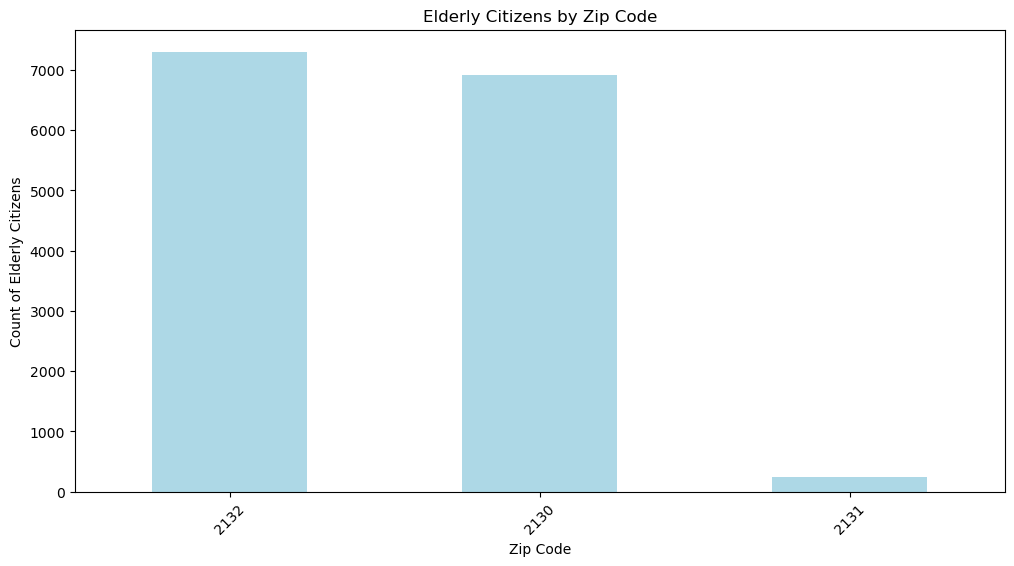

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

# Group by zip code and count the number of elderly citizens
elderly_zip_counts = df[df['Age_60_or_Above'] == True].groupby('Zip').size()

# Plot the distribution
plt.figure(figsize=(12, 6))
elderly_zip_counts.sort_values(ascending=False).plot(kind='bar', color='lightblue')
plt.title('Elderly Citizens by Zip Code')
plt.xlabel('Zip Code')
plt.ylabel('Count of Elderly Citizens')
plt.xticks(rotation=45)
plt.show()

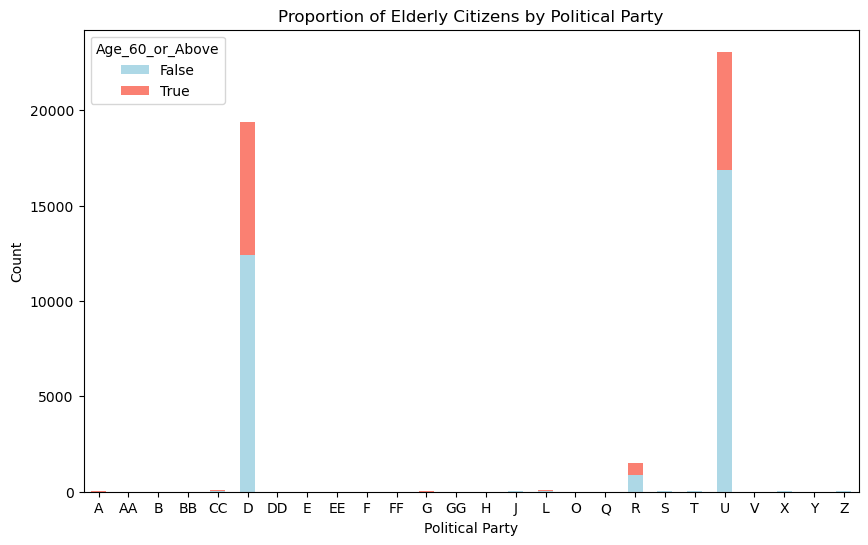

In [19]:
# Group by party affiliation and Age_55_or_Above
elderly_party_counts = df.groupby(['Party', 'Age_60_or_Above']).size().unstack(fill_value=0)

# Plot the data
elderly_party_counts.plot(kind='bar', stacked=True, figsize=(10, 6), color=['lightblue', 'salmon'])
plt.title('Proportion of Elderly Citizens by Political Party')
plt.xlabel('Political Party')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.show()

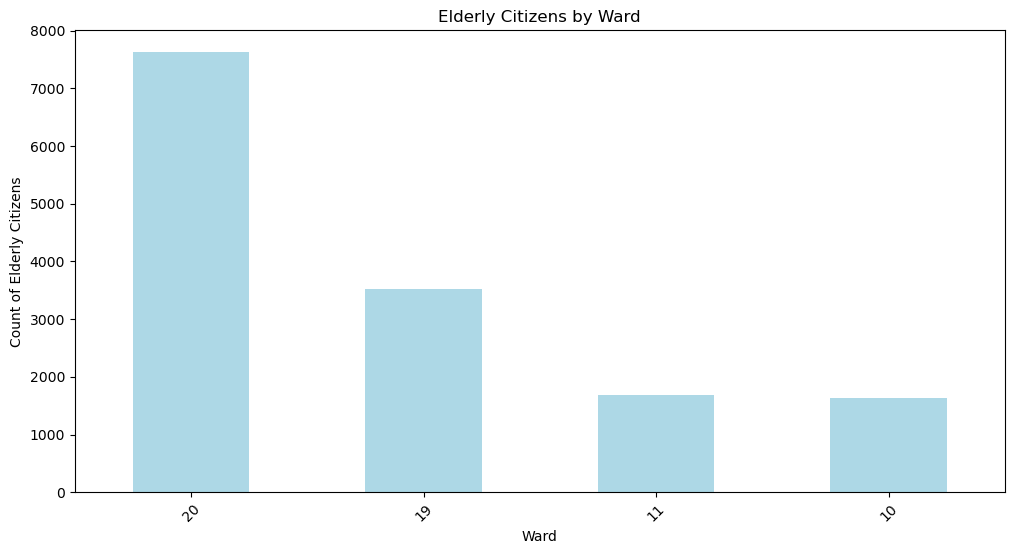

In [20]:
# Group by ward and count elderly citizens
elderly_ward_counts = df[df['Age_60_or_Above'] == True].groupby('Ward').size()

# Plot the distribution
plt.figure(figsize=(12, 6))
elderly_ward_counts.sort_values(ascending=False).plot(kind='bar', color='lightblue')
plt.title('Elderly Citizens by Ward')
plt.xlabel('Ward')
plt.ylabel('Count of Elderly Citizens')
plt.xticks(rotation=45)
plt.show()

/var/folders/5t/rl408cjx3wb2z3zq07qsqpnr0000gn/T/ipykernel_50403/791602211.py:22: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  age_zip_distribution = df.groupby(['Zip', 'Age Group']).size().unstack(fill_value=0)


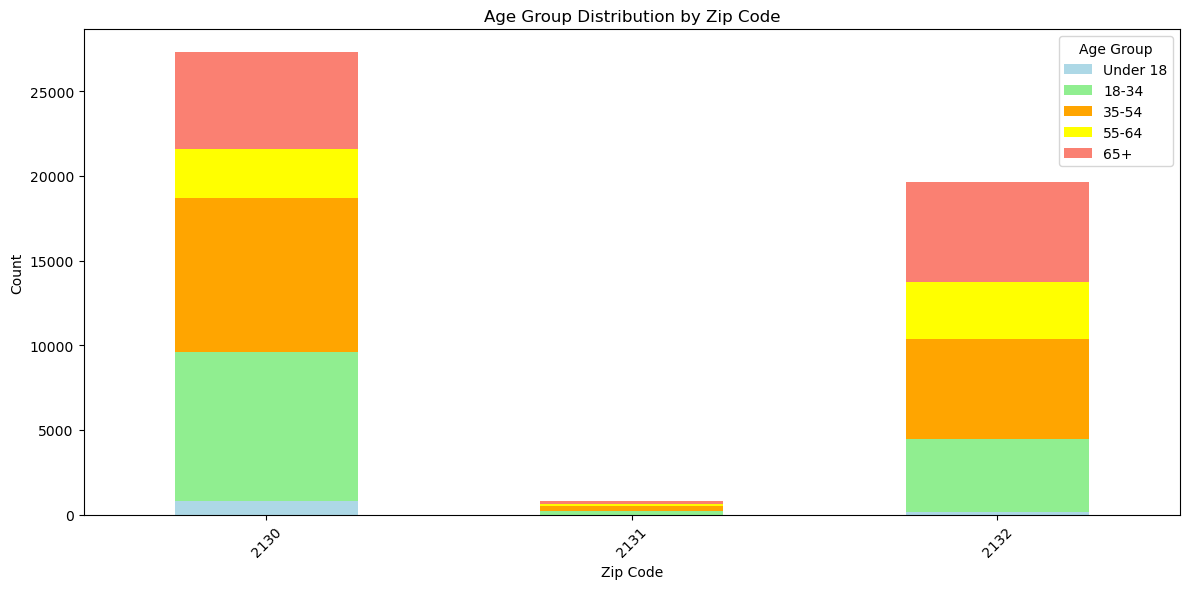

In [26]:
bins = [0, 17, 34, 54, 64, float('inf')]  # Defining the bins
labels = ['Under 18', '18-34', '35-54', '55-64', '65+']  # Labeling the bins
df['Age Group'] = pd.cut(df['Age'], bins=bins, labels=labels, right=False)

# Group by Zip and Age Group and count occurrences
age_zip_distribution = df.groupby(['Zip', 'Age Group']).size().unstack(fill_value=0)

# Define colors for each age group
colors = ['lightblue', 'lightgreen', 'orange', 'yellow', 'salmon']

# Plot the distribution
ax = age_zip_distribution.plot(kind='bar', stacked=True, figsize=(12, 6), color=colors)

# Set chart title and labels
plt.title('Age Group Distribution by Zip Code')
plt.xlabel('Zip Code')
plt.ylabel('Count')

# Rotate x-tick labels for better readability
plt.xticks(rotation=45)

# Display the chart
plt.tight_layout()  # To prevent clipping of labels
plt.show()

/var/folders/5t/rl408cjx3wb2z3zq07qsqpnr0000gn/T/ipykernel_50403/3760895663.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  age_ward_distribution = df.groupby(['Ward', 'Age Group']).size().unstack(fill_value=0)


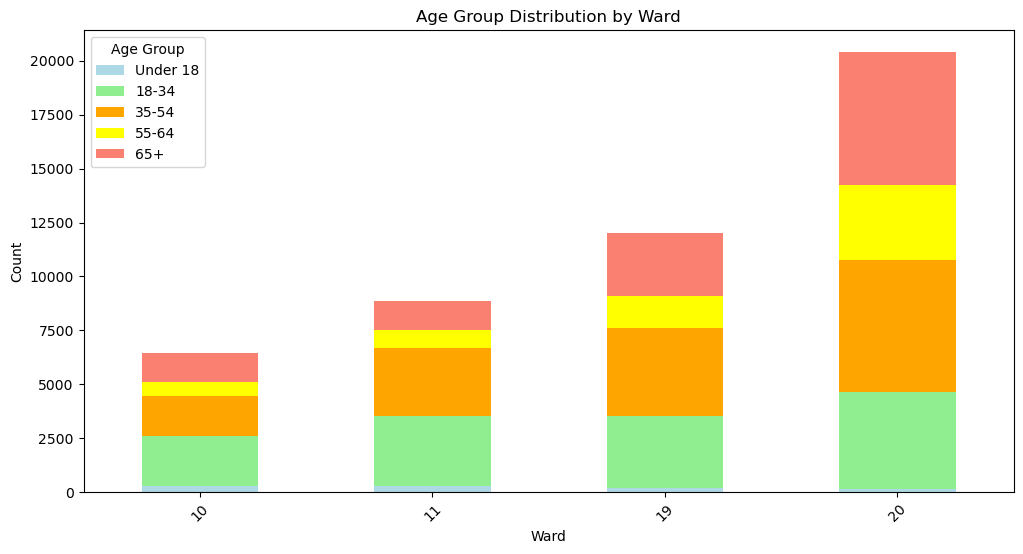

In [28]:
# Group by ward and age group and count occurrences
age_ward_distribution = df.groupby(['Ward', 'Age Group']).size().unstack(fill_value=0)

colors = ['lightblue', 'lightgreen', 'orange', 'yellow', 'salmon']

# Plot the distribution
age_ward_distribution.plot(kind='bar', stacked=True, figsize=(12, 6), color = colors)
plt.title('Age Group Distribution by Ward')
plt.xlabel('Ward')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()

/var/folders/5t/rl408cjx3wb2z3zq07qsqpnr0000gn/T/ipykernel_50403/2317118603.py:9: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  age_zip_distribution = df.groupby(['Zip', 'Age Group']).size().unstack(fill_value=0)


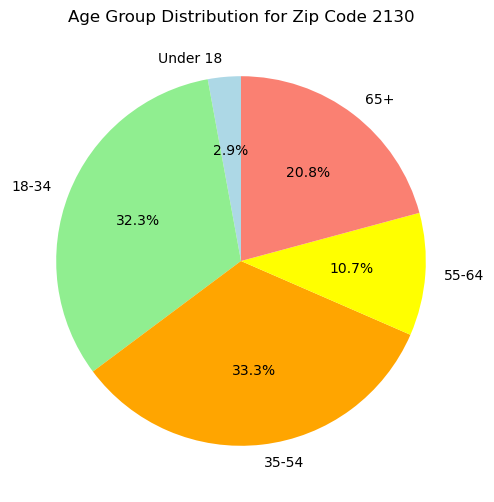

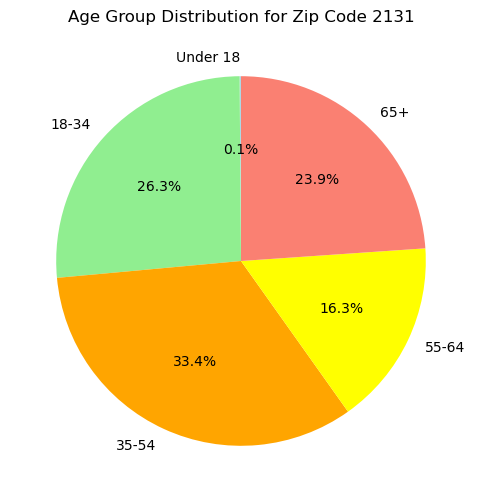

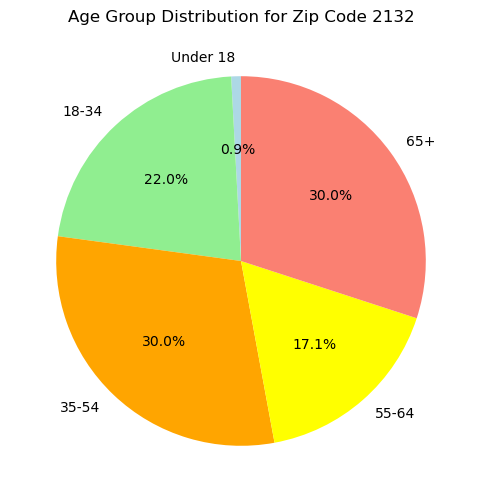

In [14]:
import matplotlib.pyplot as plt

# Create age groups
bins = [0, 17, 34, 54, 64, float('inf')]
labels = ['Under 18', '18-34', '35-54', '55-64', '65+']
df['Age Group'] = pd.cut(df['Age'], bins=bins, labels=labels, right=False)

# Group by Zip and Age Group and count occurrences
age_zip_distribution = df.groupby(['Zip', 'Age Group']).size().unstack(fill_value=0)

# Create pie chart for each zip code
for zip_code, age_distribution in age_zip_distribution.iterrows():
    # Plot pie chart for each zip code
    plt.figure(figsize=(6, 6))
    age_distribution.plot(kind='pie', autopct='%1.1f%%', startangle=90, colors=['lightblue', 'lightgreen', 'orange', 'yellow', 'salmon'])
    plt.title(f'Age Group Distribution for Zip Code {zip_code}')
    plt.ylabel('')  # Hide the y-label for aesthetics
    plt.show()

/var/folders/5t/rl408cjx3wb2z3zq07qsqpnr0000gn/T/ipykernel_50403/2065659908.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  age_group_distribution = df.groupby('Age Group').size()


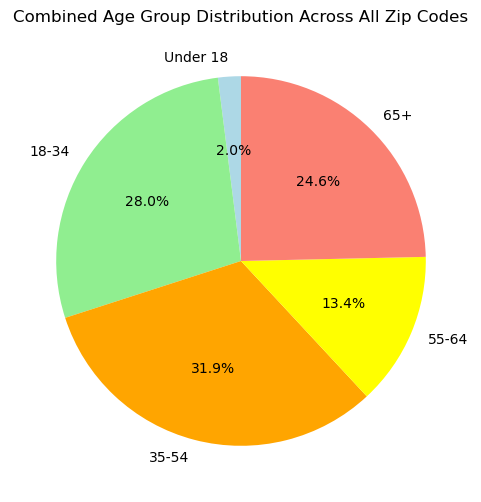

In [15]:
# Group by Age Group and count occurrences across all Zip codes
age_group_distribution = df.groupby('Age Group').size()

# Plot a pie chart for all zip codes combined
plt.figure(figsize=(6, 6))
age_group_distribution.plot(kind='pie', autopct='%1.1f%%', startangle=90, colors=['lightblue', 'lightgreen', 'orange', 'yellow', 'salmon'])
plt.title('Combined Age Group Distribution Across All Zip Codes')
plt.ylabel('')  # Hide the y-label for aesthetics
plt.show()

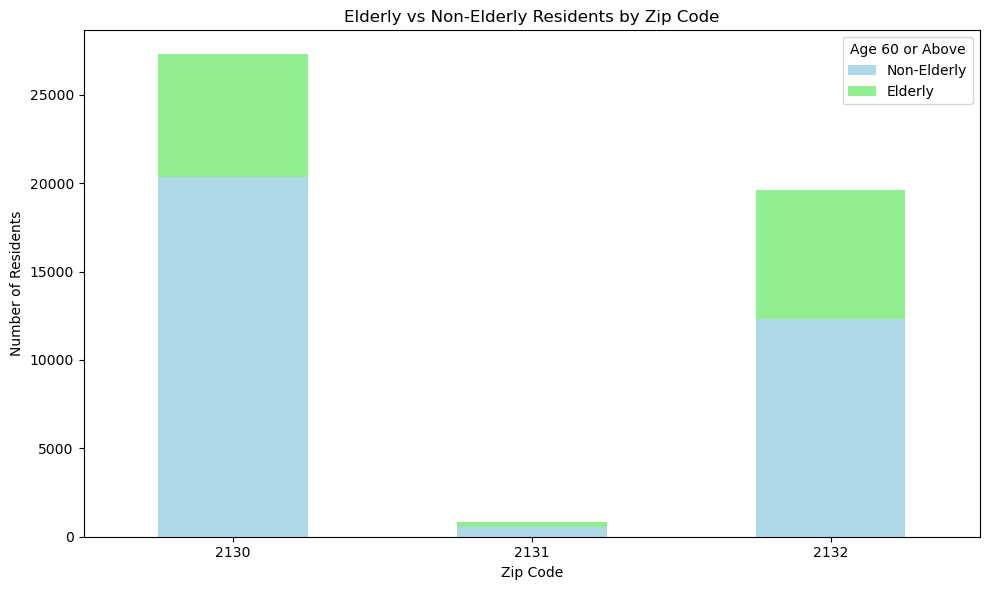

In [29]:
age_distribution = df.groupby(['Zip', 'Age_60_or_Above']).size().unstack(fill_value=0)

ax = age_distribution.plot(kind='bar', stacked=True, figsize=(10, 6), color=['lightblue', 'lightgreen'])
plt.title('Elderly vs Non-Elderly Residents by Zip Code')
plt.xlabel('Zip Code')
plt.ylabel('Number of Residents')
plt.xticks(rotation=0)
plt.legend(['Non-Elderly', 'Elderly'], title='Age 60 or Above')
plt.tight_layout()
plt.show()

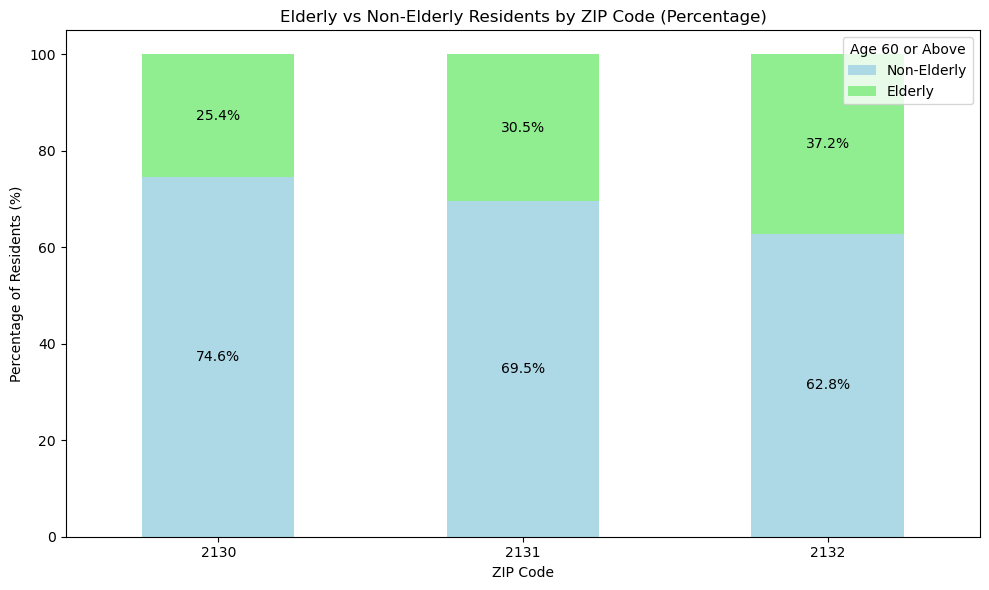

In [30]:
age_distribution = df.groupby(['Zip', 'Age_60_or_Above']).size().unstack(fill_value=0)

age_distribution_percentage = age_distribution.div(age_distribution.sum(axis=1), axis=0) * 100

ax = age_distribution_percentage.plot(kind='bar', stacked=True, figsize=(10, 6), color=['lightblue', 'lightgreen'])

for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f'{height:.1f}%', 
                    (p.get_x() + p.get_width() / 2., p.get_y() + height / 2.),
                    ha='center', va='center', fontsize=10, color='black')

plt.title('Elderly vs Non-Elderly Residents by ZIP Code (Percentage)')
plt.xlabel('ZIP Code')
plt.ylabel('Percentage of Residents (%)')
plt.xticks(rotation=0)
plt.legend(['Non-Elderly', 'Elderly'], title='Age 60 or Above')
plt.tight_layout()
plt.show()